# MD Trajectory Visualization — CDK2_ERK2 / single_a / mol_0

2D plots (RMSD, RMSF, Rg, H-bonds) + 3D interactive trajectory viewer.

In [ ]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams.update({
    'figure.dpi': 150,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 12,
})

# Ensure we're in the output directory regardless of where Jupyter started
os.chdir(Path(__file__).parent if '__file__' in dir() else Path.cwd())
# If notebook is at /mnt/data/SWW2026/output/md_visualize.ipynb, data is in output/md/
HERE = Path('/mnt/data/SWW2026/output')
os.chdir(HERE)

PLOTS = HERE / 'md_plots'
PLOTS.mkdir(exist_ok=True)

BASE = HERE / 'md' / 'CDK2_ERK2' / 'single_a' / 'mol_0'
targets = {
    'CDK2 (target A)': BASE / 'target_A',
    'ERK2 (target B)': BASE / 'target_B',
}
colors = {'CDK2 (target A)': '#2563eb', 'ERK2 (target B)': '#dc2626'}
print('CWD:', os.getcwd())
print('Data dirs:', {k: v.exists() for k, v in targets.items()})
for k, v in targets.items():
    csvs = list(v.glob('*.csv'))
    print(f'  {k}: {len(csvs)} CSV files')

## 1. Ligand RMSD over time
How much the ligand deviates from its starting pose. <3.0 Å = stable binding.

FileNotFoundError: [Errno 2] No such file or directory: 'md/CDK2_ERK2/single_a/mol_0/target_A/rmsd_ligand.csv'

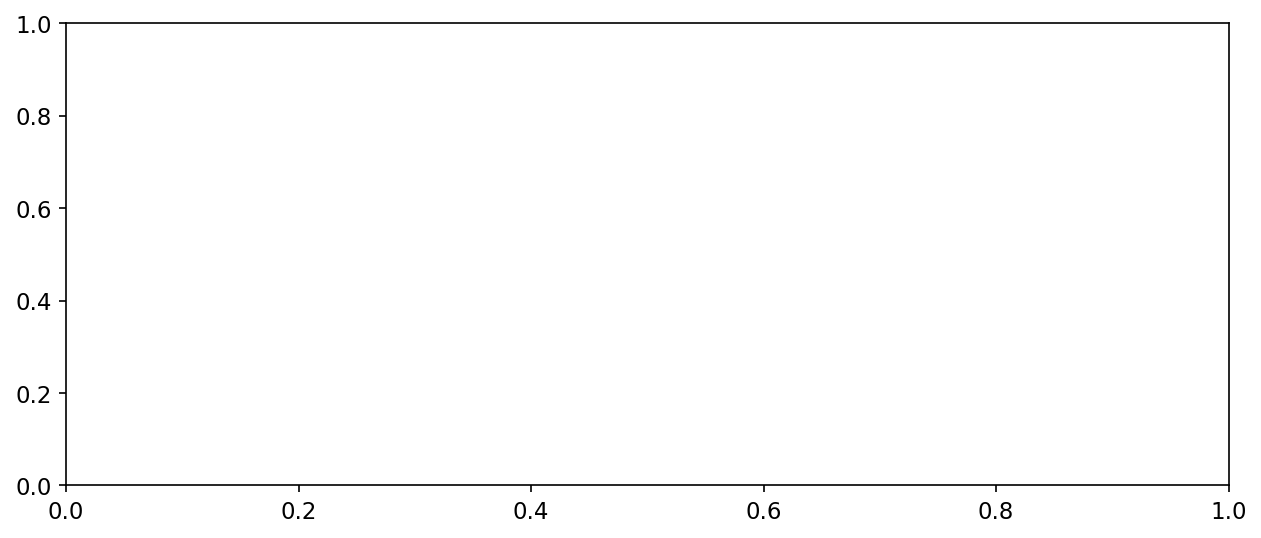

In [2]:
fig, ax = plt.subplots(figsize=(10, 4))
for label, d in targets.items():
    df = pd.read_csv(d / 'rmsd_ligand.csv')
    ax.plot(df['time_ns'], df['rmsd_A'], label=label, color=colors[label], linewidth=0.8)
ax.axhline(3.0, color='gray', linestyle='--', linewidth=0.8, label='Stability threshold (3.0 Å)')
ax.set_xlabel('Time (ns)')
ax.set_ylabel('Ligand RMSD (Å)')
ax.set_title('Ligand RMSD — Binding Stability')
ax.legend()
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.savefig(PLOTS / 'ligand_rmsd.png', dpi=300, bbox_inches='tight')
plt.show()

## 2. Backbone RMSD over time
Overall protein stability. <2.0 Å = very stable, <3.0 Å = acceptable.

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
for label, d in targets.items():
    df = pd.read_csv(d / 'rmsd_backbone.csv')
    ax.plot(df['time_ns'], df['rmsd_A'], label=label, color=colors[label], linewidth=0.8)
ax.set_xlabel('Time (ns)')
ax.set_ylabel('Backbone RMSD (Å)')
ax.set_title('Backbone RMSD — Protein Stability')
ax.legend()
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.savefig(PLOTS / 'backbone_rmsd.png', dpi=300, bbox_inches='tight')
plt.show()

## 3. Per-residue RMSF
Thermal fluctuation per residue. High RMSF = flexible loop/terminus.

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4))
for label, d in targets.items():
    df = pd.read_csv(d / 'rmsf.csv')
    ax.plot(df['residue'], df['rmsf_A'], label=label, color=colors[label], linewidth=0.6, alpha=0.8)
ax.set_xlabel('Residue number')
ax.set_ylabel('RMSF (Å)')
ax.set_title('Per-Residue RMSF — Flexibility Profile')
ax.legend()
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.savefig(PLOTS / 'rmsf.png', dpi=300, bbox_inches='tight')
plt.show()

## 4. Radius of Gyration
Compactness of the protein. Constant Rg = protein doesn't unfold.

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
for label, d in targets.items():
    df = pd.read_csv(d / 'radius_gyration.csv')
    time_ns = df['time_ps'] / 1000.0
    ax.plot(time_ns, df['rg_A'], label=label, color=colors[label], linewidth=0.8)
ax.set_xlabel('Time (ns)')
ax.set_ylabel('Radius of Gyration (Å)')
ax.set_title('Radius of Gyration — Protein Compactness')
ax.legend()
plt.tight_layout()
plt.savefig(PLOTS / 'radius_gyration.png', dpi=300, bbox_inches='tight')
plt.show()

## 5. Hydrogen Bonds
Protein-ligand hydrogen bond count over time.

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
for label, d in targets.items():
    df = pd.read_csv(d / 'hbonds.csv')
    if not df.empty and 'time_ns' in df.columns:
        ax.plot(df['time_ns'], df['n_hbonds'], label=label, color=colors[label], linewidth=0.8, alpha=0.7)
ax.set_xlabel('Time (ns)')
ax.set_ylabel('Number of H-bonds')
ax.set_title('Protein–Ligand Hydrogen Bonds')
ax.legend()
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.savefig(PLOTS / 'hbonds.png', dpi=300, bbox_inches='tight')
plt.show()

## 6. Summary Dashboard
All key metrics in one panel.

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Ligand RMSD
ax = axes[0, 0]
for label, d in targets.items():
    df = pd.read_csv(d / 'rmsd_ligand.csv')
    ax.plot(df['time_ns'], df['rmsd_A'], label=label, color=colors[label], linewidth=0.7)
ax.axhline(3.0, color='gray', ls='--', lw=0.7)
ax.set_title('Ligand RMSD')
ax.set_ylabel('RMSD (Å)')
ax.set_ylim(bottom=0)
ax.legend(fontsize=9)

# Backbone RMSD
ax = axes[0, 1]
for label, d in targets.items():
    df = pd.read_csv(d / 'rmsd_backbone.csv')
    ax.plot(df['time_ns'], df['rmsd_A'], label=label, color=colors[label], linewidth=0.7)
ax.set_title('Backbone RMSD')
ax.set_ylabel('RMSD (Å)')
ax.set_ylim(bottom=0)
ax.legend(fontsize=9)

# RMSF
ax = axes[1, 0]
for label, d in targets.items():
    df = pd.read_csv(d / 'rmsf.csv')
    ax.plot(df['residue'], df['rmsf_A'], label=label, color=colors[label], linewidth=0.5, alpha=0.8)
ax.set_title('Per-Residue RMSF')
ax.set_xlabel('Residue')
ax.set_ylabel('RMSF (Å)')
ax.set_ylim(bottom=0)
ax.legend(fontsize=9)

# Radius of Gyration
ax = axes[1, 1]
for label, d in targets.items():
    df = pd.read_csv(d / 'radius_gyration.csv')
    ax.plot(df['time_ps']/1000, df['rg_A'], label=label, color=colors[label], linewidth=0.7)
ax.set_title('Radius of Gyration')
ax.set_xlabel('Time (ns)')
ax.set_ylabel('Rg (Å)')
ax.legend(fontsize=9)

fig.suptitle('MD Validation — CDK2_ERK2 / single_a / mol_0 (10 ns)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(PLOTS / 'md_dashboard.png', dpi=300, bbox_inches='tight')
plt.show()

---
## 7. 3D Trajectory Viewer (NGLview)

Interactive 3D visualization of the protein-ligand complex trajectory.
Uses GRO (reference structure) + XTC (trajectory).

**Controls**: drag to rotate, scroll to zoom, click ▶ to play animation.

In [ ]:
import MDAnalysis as mda
import nglview as nv

# Choose target: 'target_A' (CDK2) or 'target_B' (ERK2)
target = 'target_B'
target_label = 'ERK2' if target == 'target_B' else 'CDK2'
d = BASE / target

# reference.gro from new runs, reference_npt.gro from legacy
gro_path = d / 'reference.gro'
if not gro_path.exists():
    gro_path = d / 'reference_npt.gro'
gro = str(gro_path)
xtc = str(d / 'trajectory.xtc')

u = mda.Universe(gro, xtc)
print(f'Loaded {target_label}: {u.atoms.n_atoms} atoms, {u.trajectory.n_frames} frames')

# Select protein + ligand only (skip water/ions for clarity)
protein_lig = u.select_atoms('protein or resname LIG')
print(f'Protein+Ligand: {protein_lig.n_atoms} atoms')

In [ ]:
# Interactive 3D viewer
view = nv.show_mdanalysis(protein_lig)

# Protein: blue cartoon + transparent surface
# Ligand: orange ball-and-stick
view.clear_representations()
view.add_cartoon(selection='protein', color='skyblue', opacity=0.85)
view.add_ball_and_stick(selection='LIG', color='orange')
view.add_surface(selection='protein', opacity=0.15, color='lightgray')

view.center('LIG')
view.camera = 'perspective'

print(f'3D Viewer: {target_label} — drag to rotate, scroll to zoom, ▶ to play')
view

## 8. Ligand COM trajectory in 3D space

Static plot: ligand center-of-mass position over time. Color = time progression (blue→red).

In [ ]:
for target, target_label in [('target_A', 'CDK2'), ('target_B', 'ERK2')]:
    d = BASE / target
    gro_path = d / 'reference.gro'
    if not gro_path.exists():
        gro_path = d / 'reference_npt.gro'
    u = mda.Universe(str(gro_path), str(d / 'trajectory.xtc'))
    lig = u.select_atoms('resname LIG')
    positions = []
    for ts in u.trajectory:
        positions.append(lig.center_of_mass().copy())
    positions = np.array(positions)

    fig = plt.figure(figsize=(7, 7))
    ax = fig.add_subplot(111, projection='3d')
    sc = ax.scatter(positions[:, 0], positions[:, 1], positions[:, 2],
                    c=np.arange(len(positions)), cmap='coolwarm', s=8, alpha=0.6)
    ax.set_xlabel('X (Å)')
    ax.set_ylabel('Y (Å)')
    ax.set_zlabel('Z (Å)')
    ax.set_title(f'Ligand COM Trajectory — {target_label}')
    plt.colorbar(sc, label='Frame', shrink=0.6)
    plt.tight_layout()
    plt.savefig(PLOTS / f'ligand_com_3d_{target_label}.png', dpi=300, bbox_inches='tight')
    plt.show()
    disp = np.linalg.norm(positions[-1] - positions[0])
    span = np.max(np.linalg.norm(positions - positions.mean(axis=0), axis=1))
    print(f'{target_label}: displacement={disp:.2f} Å, max span from mean={span:.2f} Å')